<a href="https://colab.research.google.com/github/anupbagale/image-processing-from-scratch/blob/main/notebooks/09_entropy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Entropy

The entropy of an image measures how much information its pixel values carry. If $p_k$ is the
fraction of pixels with grey level $k$, the entropy in bits per pixel is

$$H = -\sum_{k=0}^{255} p_k \log_2 p_k$$

(grey levels that do not appear are skipped, since $p \log p \to 0$).

An image where every pixel has the same value has $H = 0$. An 8-bit image where all 256 values are
equally common has the maximum, $H = 8$. Entropy is also the lower limit on the average number of
bits per pixel that any code can reach when it encodes each pixel separately, which is why it
comes back in the Huffman coding notebook.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from skimage import data

plt.rcParams["image.cmap"] = "gray"

In [2]:
def entropy(image):
    histogram = np.bincount(image.ravel(), minlength=256)
    p = histogram / histogram.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log2(p))) + 0.0   # + 0.0 turns -0.0 into 0.0

The first version of this notebook imported OpenCV as `cv` but then called `cv2.imread`, so it
only ran in a session where `cv2` had already been imported somewhere else.

## Entropy of a few images

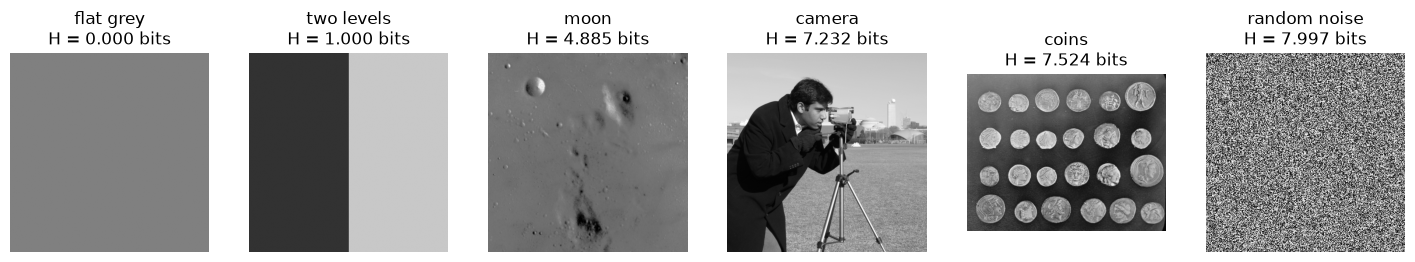

In [3]:
rng = np.random.default_rng(0)
images = {
    "flat grey": np.full((256, 256), 128, dtype=np.uint8),
    "two levels": np.where(np.arange(256)[None, :] < 128, 50, 200).repeat(256, axis=0).astype(np.uint8),
    "moon": data.moon(),
    "camera": data.camera(),
    "coins": data.coins(),
    "random noise": rng.integers(0, 256, (256, 256), dtype=np.uint8),
}

fig, ax = plt.subplots(1, len(images), figsize=(18, 3.6))
for a, (name, img) in zip(ax, images.items()):
    a.imshow(img, vmin=0, vmax=255)
    a.set_title(f"{name}\nH = {entropy(img):.3f} bits")
    a.axis("off")
plt.show()

- The flat image has no uncertainty at all, so $H = 0$.
- The image with two equally common values needs exactly 1 bit per pixel.
- The moon image is low contrast and uses only a narrow range of grey levels, so its entropy is
  much lower than that of the camera and coins images.
- Random noise is close to the maximum of 8 bits, even though it looks like nothing. Entropy
  measures how unpredictable the pixel values are, not how meaningful the picture is.

## Comparison with scikit-image

In [4]:
from skimage.measure import shannon_entropy

for name, img in images.items():
    print(f"{name:<13} ours: {entropy(img):.4f}   skimage: {shannon_entropy(img):.4f}")

flat grey     ours: 0.0000   skimage: 0.0000
two levels    ours: 1.0000   skimage: 1.0000
moon          ours: 4.8850   skimage: 4.8850
camera        ours: 7.2317   skimage: 7.2317
coins         ours: 7.5244   skimage: 7.5244
random noise  ours: 7.9974   skimage: 7.9974
